# 7. Nonlinear iteration test - Python

1. Edit the inputs below and **Restart Kernel and Run All**.
2. Run `nonlinear_iteration_test.mlx` in MATLAB (same code as the `.m`).
3. Run `compare_results.ipynb`.

One editable five-cavity case, with the same frequencies as test 5.
Python runs `large_signal_1d.solve()`. MATLAB independently calculates
its grid, Gaussian profiles, initial states and nonlinear solution from
**raw inputs only**, using copied original MATLAB code.

This tests the current translation: both solvers leave the cavity tracking
fields `Emz` and `Emz0` zero. It is not a cavity-induced gain validation.
There are no animation scripts or GIFs in this test.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat

# Find pyKlyC whether the kernel starts in this folder or in the project.
current = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current, *current.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "large_signal_1d.py").is_file()
)
test_directory = project_directory / "test" / "7.nonlinear_iteration_test"
sys.path.insert(0, str(project_directory / "src"))

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True,
    "grid.color": "gray", "grid.linestyle": "--", "grid.alpha": 0.45,
})
np.set_printoptions(precision=6, linewidth=120)

In [2]:
from uuid import uuid4
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.cavity_field_map import CavityFieldMap
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters
from solver.cavity_fields import CavityFields
from solver.large_signal_1d import solve

## 1. Inputs

Units follow MATLAB: frequency in GHz, positions in mm, voltage in kV,
current in A and input RF power in W. The entrance current is modulated.
Set `Izt = -16*np.ones(Nt)` for a uniform beam instead.

`factor` multiplies the plasma frequency. The modest default keeps this
first full-loop comparison easy to inspect. `evolutionmethod[1] = 2`
normally selects global space charge after the first pass; setting it to
`Rlimit` requests a local-only run. `Nlimit` is a maximum, not a requested
number of evaluated iterations. This notebook uses no power ramp.

In [3]:
# Entrance beam.
Nbeam = 1
Nt = 64
rm1, rm2, rc = 0.0, 6.0, 10.0
t0 = 2*np.pi*np.arange(Nt)/Nt
tn1 = t0.copy()
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)
Izt = -16.0*(1 + 0.20*np.cos(t0) + 0.05*np.cos(2*t0))

# Input cavity, three bunching cavities, output cavity.
Nc = 5
f = 1.0
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])
RtoQ = np.array([182.8959, 116.9999, 102.0570, 123.6318, 180.3864])
M = np.array([0.9225, 0.8930, 0.8192, 0.9518, 0.9325])
type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
Qext = np.array([334., 95000., 95000., 95000., 50.])
Qin = np.array([16428., 19768., 19816., 16970., 14787.])
zshift = np.array([0., 480., 1630., 2400., 2730.])
Pin = np.array([60., 0., 0., 0., 0.])
gaman = np.zeros(Nc, dtype=complex)
kai = np.zeros((Nc, Nc), dtype=complex)
Lsb = np.pi*np.ones(Nc)
cavityname = "C1 C2 C3 C4 C5"

# Gaussian sampling, tube and longitudinal grid.
N = 200
z0, L = -100.0, 3000.0
rcv = np.array([[z0, z0 + L], [1., 1.]])
Nz, Ns = 64, 3
factorregion = 10.0

# Nonlinear iteration and space charge.
Nlimit, Ntimes = 30, 5
Rlimit, iterfactor = 1e-4, 0.5
evolutionmethod = np.array([0.005, 2.0])
factor, fillfactor, DCSPfactor = 0.1, 1.0, 1.0
upstream_discard_distance_mm = 0.0
efficiency_end_offset_mm = 3*rc

## 2. Build the Python input objects and cavity profiles

In [4]:
beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc, xb=0., yb=0., xd=0., yd=0.,
    Nt=Nt, t0=t0, tn1=tn1, Y0=Y0, Ut=Ut, Izt=Izt,
)
numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=Nlimit, Ntimes=Ntimes,
    Rlimit=Rlimit, iterfactor=iterfactor, evolutionmethod=evolutionmethod,
    upstream_discard_distance_mm=upstream_discard_distance_mm,
    efficiency_end_offset_mm=efficiency_end_offset_mm,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin, zshift=zshift, Pin=Pin,
    gaman=gaman, Lsb=Lsb, kai=kai, cavityname=cavityname,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(numerical, cavities, tube, beam, reference, factorregion)
maps = CavityFieldMap.from_circuit_parameters(cavities.names, f0, RtoQ, M, reference.s, N)
cavity_fields = CavityFields.calculate(numerical, cavities, grid, reference, maps)

print("Grid points:", len(grid.z), "  dz [mm]:", grid.dz)
print("Reference voltage [kV]:", reference.U0, "  reference speed/c:", reference.s)

Grid points: 952   dz [mm]: 3.1545741324921135
Reference voltage [kV]: 180.0   reference speed/c: 0.6731458398741619


## 3. Solve and record convergence

The callback records only scalars. Voltages, drive factors and SC methods
are already stored by `solve()`. It does not modify any solver state.
The first pass has zero tracking space charge, as in the MATLAB source.

In [5]:
iterations = []
effend_history = []
residential_history = []
residentialel_history = []

def record_iteration(record, beam_state, cavity_state, space_charge_state, dynamics):
    iterations.append(record.iteration)
    effend_history.append(record.effend)
    residential_history.append(record.residential)
    residentialel_history.append(record.residentialel)

result = solve(
    numerical, beam, cavities, grid, reference, cavity_fields,
    factor=factor, fillfactor=fillfactor, DCSPfactor=DCSPfactor,
    on_iteration=record_iteration,
)
print("Stop reason:", result.control.reason)
print("Last attempted iteration:", result.nn)
print("Evaluated iterations:", len(iterations))
print("SC method in each pass:", result.SCmethods)
print("Final Vnc:", result.cavity_state.Vnc)

C:\Users\lsito\AppData\Local\Temp\ipykernel_23392\1610552865.py:12: RuntimeWarning: The available MATLAB source leaves cavity tracking fields Emz and Emz0 at zero. This solve preserves that behavior: cavity-to-beam acceleration is absent, even if the voltage iterations converge.
  result = solve(


Stop reason: converged
Last attempted iteration: 16
Evaluated iterations: 16
SC method in each pass: [0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Final Vnc: [-0.00275 -1.408454j -0.197222-0.197851j  0.080705-0.039787j  0.046661+0.039399j  0.030499+0.205231j]


## 4. Inspect the final state and convergence

`Esz`/`Esz0` are space charge, `Emz`/`Emz0` are cavity contributions,
and `Esmz`/`Esmz0` are the totals used for tracking. These curves show
harmonic coefficients; an instantaneous particle field also depends on
its arrival phase. The final beam is relaxed; fields belong to the last pass.

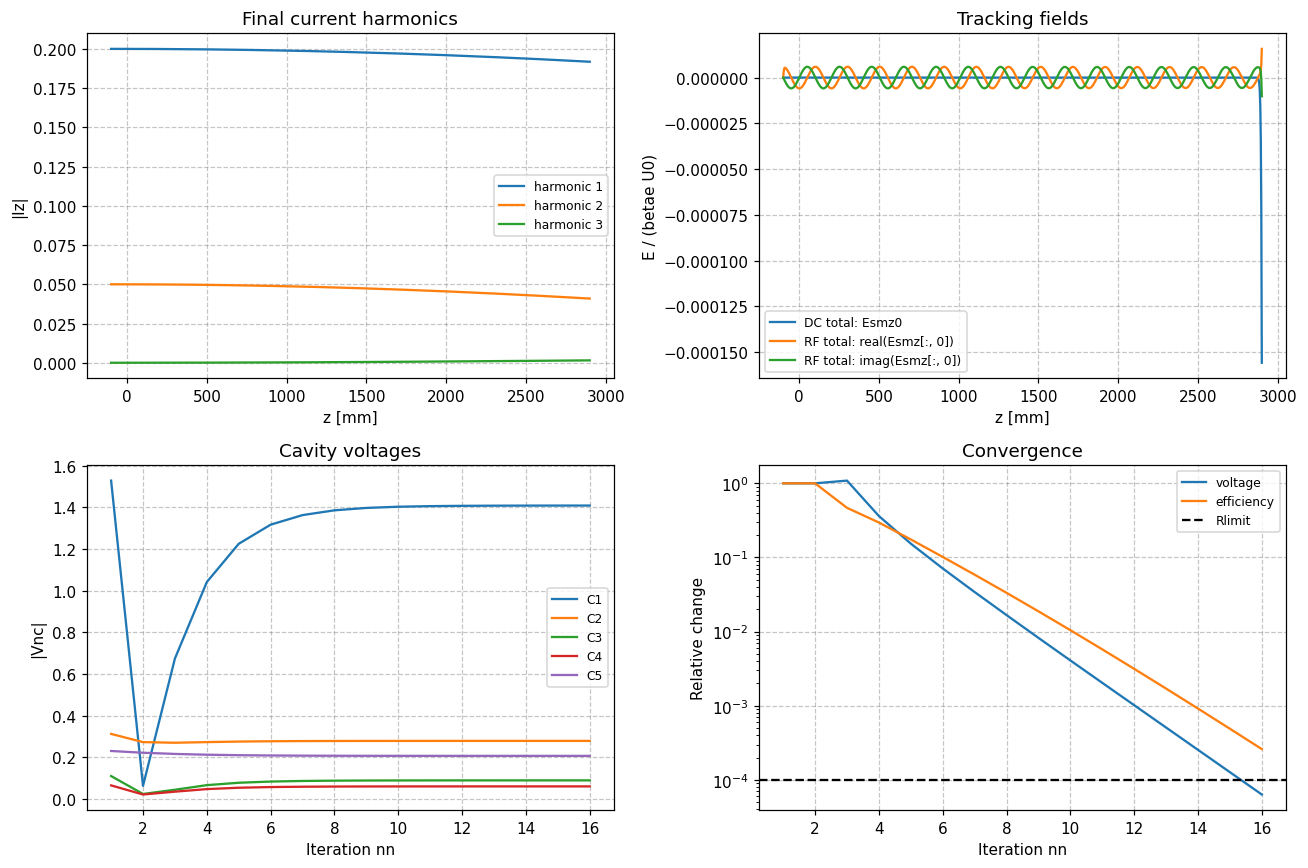

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for k in range(Ns):
    axes[0, 0].plot(grid.zi, abs(result.beam_state.Iz[:, k]), label=f"harmonic {k+1}")
axes[0, 0].set(xlabel="z [mm]", ylabel="|Iz|", title="Final current harmonics")

axes[0, 1].plot(grid.zi, result.Esmz0.real, label="DC total: Esmz0")
axes[0, 1].plot(grid.zi, result.Esmz[:, 0].real, label="RF total: real(Esmz[:, 0])")
axes[0, 1].plot(grid.zi, result.Esmz[:, 0].imag, label="RF total: imag(Esmz[:, 0])")
axes[0, 1].set(xlabel="z [mm]", ylabel="E / (betae U0)", title="Tracking fields")

for k, name in enumerate(cavities.names):
    axes[1, 0].plot(iterations, abs(result.Vnc_history[:, k]), label=name)
axes[1, 0].set(xlabel="Iteration nn", ylabel="|Vnc|", title="Cavity voltages")

# The floor is only for displaying zero residuals on a logarithmic axis.
axes[1, 1].semilogy(iterations, np.maximum(residential_history, 1e-15), label="voltage")
axes[1, 1].semilogy(iterations, np.maximum(residentialel_history, 1e-15), label="efficiency")
axes[1, 1].axhline(Rlimit, color="black", linestyle="--", label="Rlimit")
axes[1, 1].set(xlabel="Iteration nn", ylabel="Relative change", title="Convergence")
for axis in axes.flat:
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Export raw inputs and Python results

`inputs.mat` contains only input parameters and entrance samples, never
Python-derived starting fields or states. MATLAB calculates those itself.
`Y0` is exported one-based. Each export creates a new `run_id`, so the
comparison rejects an older MATLAB result. These two files are overwritten
on rerun; rerun MATLAB afterwards.

In [7]:
run_id = uuid4().hex
inputs = dict(
    run_id=run_id, Nbeam=Nbeam, Nt=Nt, rm1=rm1, rm2=rm2, rc=rc,
    xb=0., yb=0., xd=0., yd=0., t0=t0, tn1=tn1, Y0=Y0+1, Ut=Ut, Izt=Izt,
    Nc=Nc, f=f, f0=f0, RtoQ=RtoQ, M=M, type=type, nh=nh,
    Qext=Qext, Qin=Qin, zshift=zshift, Pin=Pin, gaman=gaman,
    kai=kai, Lsb=Lsb, cavityname=cavityname, N=N, Nr=1,
    z0=z0, L=L, rcv=rcv, Nz=Nz, Ns=Ns, factorregion=factorregion,
    Nlimit=Nlimit, Ntimes=Ntimes, Rlimit=Rlimit, iterfactor=iterfactor,
    evolutionmethod=evolutionmethod, factor=factor,
    fillfactor=fillfactor, DCSPfactor=DCSPfactor,
    mono=1, Npin=1, moviedisp=np.array([0, 0, 0, 0, 1]),
    GIFpara=np.array([8, 0, 1, upstream_discard_distance_mm, efficiency_end_offset_mm, 0]),
)
# MATLAB arithmetic uses doubles, including counts and one-based indices.
for name, value in inputs.items():
    if isinstance(value, (int, np.integer)):
        inputs[name] = float(value)
    elif isinstance(value, np.ndarray) and value.dtype.kind in "iu":
        inputs[name] = value.astype(float)
savemat(test_directory / "inputs.mat", inputs, oned_as="row")

python_results = dict(
    run_id=run_id, zi=grid.zi, z=grid.z, U0=reference.U0, I0=reference.I0,
    s=reference.s, betae=grid.betae, dt=grid.dt,
    ez=cavity_fields.ez, C3=cavity_fields.C3,
    wp=result.space_charge_state.wp, Esz00=result.space_charge_state.Esz00,
    Esz=result.space_charge_state.Esz, Esz0=result.space_charge_state.Esz0,
    Emz=result.Emz, Emz0=result.Emz0, Esmz=result.Esmz, Esmz0=result.Esmz0,
    nn=result.nn, iterationsuc=result.control.iterationsuc,
    SCmethod=result.space_charge_state.SCmethod, effendflag=result.control.effendflag,
    iterations=np.array(iterations), Vnc_history=result.Vnc_history,
    Vnp_history=result.Vnp_history, SCmethods=result.SCmethods,
    drivefactors=result.drivefactors, skipped_iterations=result.skipped_iterations,
    effend_history=np.array(effend_history), residential_history=np.array(residential_history),
    residentialel_history=np.array(residentialel_history),
)
# Store the final beam, circuit, and raw tracking quantities by MATLAB name.
for name in ["Iz", "QQ", "IzDC", "QQDC", "effe", "vez", "gamaz"]:
    python_results[name] = getattr(result.beam_state, name)
for name in ["Mc", "B", "Vnc", "Vnp", "Vin", "flagVnc"]:
    python_results[name] = getattr(result.cavity_state, name)
for name in ["Zn", "Vn", "Tn", "Tnz", "Vnz", "Utn", "ttn", "Y", "Yflag",
             "Pe", "Izr", "IzDCr", "QQr", "QQDCr"]:
    python_results[name] = getattr(result.dynamics, name)
savemat(test_directory / "python_results.mat", python_results, oned_as="row")
print("Saved inputs.mat and python_results.mat in", test_directory)
print("Now run nonlinear_iteration_test.mlx in MATLAB, then compare_results.ipynb.")

Saved inputs.mat and python_results.mat in C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\7.nonlinear_iteration_test
Now run nonlinear_iteration_test.mlx in MATLAB, then compare_results.ipynb.
